X shape: torch.Size([100, 2]) y shape: torch.Size([100, 1])
epoch   0: loss = 3173.5
epoch  50: loss = 315.2
epoch 100: loss = 163.0
epoch 150: loss = 163.0
epoch 200: loss = 163.0
epoch 250: loss = 163.0


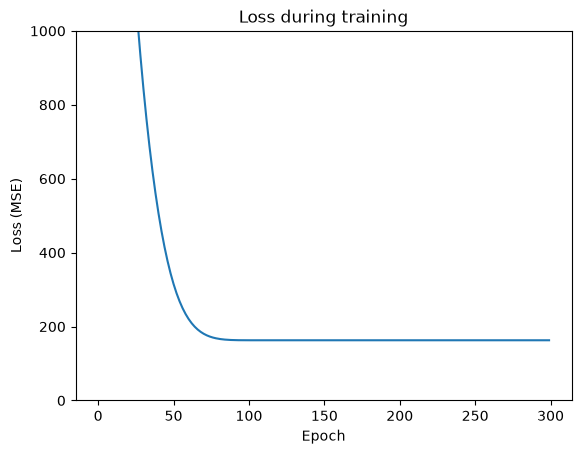

3 study hours, 2 phone hours - 53.77 marks


In [9]:

import torch
from torch import nn
import pandas as pd
import matplotlib.pyplot as plt

students = pd.read_csv("students_100.csv")

X = torch.tensor(
    students[["study_hours", "phone_hours"]].values,
    dtype=torch.float32
)

y = torch.tensor(
    students[["maths"]].values,
    dtype=torch.float32
)

print("X shape:", X.shape, "y shape:", y.shape)

torch.manual_seed(42)

model = nn.Sequential(
    nn.Linear(2, 3),
    nn.ReLU(),
    nn.Linear(3, 4),
    nn.ReLU(),
    nn.Linear(4, 1)
)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1)

losses = []

for epoch in range(300):
    guess = model(X)
    loss = loss_fn(guess, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if epoch % 50 == 0:
        print(f"epoch {epoch:3}: loss = {loss.item():.1f}")

plt.plot(losses)
plt.ylim(0, 1000)
plt.title("Loss during training")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.show()

with torch.no_grad():
    new_student = torch.tensor([[3, 2]], dtype=torch.float32)
    prediction = model(new_student)

    print("3 study hours, 2 phone hours -",round(prediction.item(), 2), "marks")






In [2]:
import torch

print(torch.__version__)

a = torch.tensor([1.0, 2.0, 3.0])
b = torch.tensor([10.0, 20.0, 30.0])

print(a + b)
print(a * 2)
print(a.mean())
print(a.shape)
marks = torch.tensor([80.0, 72.0, 91.0, 65.0])
print(marks.mean())
print(marks.shape)

2.14.1+cpu
tensor([11., 22., 33.])
tensor([2., 4., 6.])
tensor(2.)
torch.Size([3])
tensor(77.)
torch.Size([4])


In [5]:
w = torch.tensor(2.0, requires_grad=True)     # weight, track karo

prediction = w * 3                            # input 3
loss = (prediction - 12) ** 2                 # (6 - 12)² = 36

loss.backward()                               # gradient nikalo
print("loss:", loss.item())
print("gradient of w:", w.grad.item())
lr = 0.1
new_w = w.item() - lr * w.grad.item()
print("new w:", new_w)

loss: 36.0
gradient of w: -36.0
new w: 5.6


In [6]:
import torch
from torch import nn

torch.manual_seed(42)
neuron = nn.Linear(1, 1)          # ek neuron: w * x + b (weight aur bias PyTorch banata)
loss_fn = nn.MSELoss()             # galti kitni (square ka average)
optimizer = torch.optim.SGD(neuron.parameters(), lr=0.05)   # kadam kaise lene (lr = kadam ka size)

x = torch.tensor([[1.0], [2.0], [3.0], [4.0]])   # inputs (4 students)
y = torch.tensor([[3.0], [5.0], [7.0], [9.0]])   # asli jawab (y = 2x + 1)

for epoch in range(500):
    guess = neuron(x)                  # 1. guess (forward)
    loss = loss_fn(guess, y)           # 2. galti
    optimizer.zero_grad()              # 3. purana blame saaf
    loss.backward()                    # 4. naya blame (gradient) nikalo
    optimizer.step()                   # 5. weight aur bias badlo

print("weight:", neuron.weight.item())
print("bias:", neuron.bias.item())

weight: 1.9999595880508423
bias: 1.0001190900802612


In [12]:
import torch
from torch import nn
torch.manual_seed(42)
neuron = nn.Linear(1,1)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(neuron.parameters(),lr=0.05)

x = torch.tensor([[2.0], [3.0], [4.0], [5.0]])   
y = torch.tensor([[5.0], [7.0], [9.0], [11.0]])
for epoch in range(2000):
    guess = neuron(x)
    loss = loss_fn(guess,y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("weight:", neuron.weight.item())
print("bias:", neuron.bias.item())


weight: 1.9999982118606567
bias: 1.0000066757202148


In [13]:
import torch
from torch import nn

model = nn.Sequential(
    nn.Linear(4, 8),    # layer 1: 4 inputs, 8 neurons
    nn.ReLU(),           # activation
    nn.Linear(8, 1),    # layer 2: 8 inputs, 1 output
)
print(model)

n = sum(p.numel() for p in model.parameters())
print("weights + biases:", n)

Sequential(
  (0): Linear(in_features=4, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=1, bias=True)
)
weights + biases: 49


In [ ]:
import torch
from torch import nn
torch.manual_seed(42)
neuron = nn.Linear(1,1)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(neuron.parameters(),lr=0.05)

x = torch.tensor([[2.0], [3.0], [4.0], [5.0]])   
y = torch.tensor([[5.0], [7.0], [9.0], [11.0]])
for epoch in range(2000):
    guess = neuron(x)
    loss = loss_fn(guess,y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("weight:", neuron.weight.item())
print("bias:", neuron.bias.item())


weight: 1.9999982118606567
bias: 1.0000066757202148


In [ ]:
import torch
from torch import nn
torch.manual_seed(42)
neuron = nn.Linear(1,1)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(neuron.parameters(),lr=0.05)

x = torch.tensor([[2.0], [3.0], [4.0], [5.0]])   
y = torch.tensor([[5.0], [7.0], [9.0], [11.0]])
for epoch in range(2000):
    guess = neuron(x)
    loss = loss_fn(guess,y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print("weight:", neuron.weight.item())
print("bias:", neuron.bias.item())


weight: 1.9999982118606567
bias: 1.0000066757202148


(200, 4) (200,)
train: 120  validation: 40  test: 40
torch.Size([120, 4]) torch.Size([120, 1])
last train loss: 145
last validation loss: 146


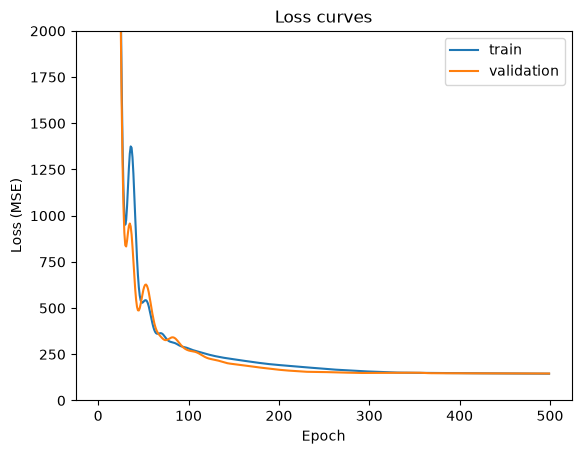

In [ ]:
import pandas as pd
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

houses = pd.read_csv("houses.csv")
X = houses[["size_marla", "bedrooms", "age_years", "distance_km"]].values     # pandas table (index aur column naam ke saath isliye .value use kiya hai sirf numbers,array ki tarah dega)
y = houses["price_lakh"].values
print(X.shape, y.shape)      
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42)
~
print("train:", len(X_train), " validation:", len(X_val), " test:", len(X_test))   
scaler = StandardScaler().fit(X_train)       # mean aur std sirf TRAIN se

def to_tensor(a):
    return torch.tensor(a, dtype=torch.float32)

X_train_t = to_tensor(scaler.transform(X_train))
X_val_t   = to_tensor(scaler.transform(X_val))
X_test_t  = to_tensor(scaler.transform(X_test))

y_train_t = to_tensor(y_train).reshape(-1, 1)
y_val_t   = to_tensor(y_val).reshape(-1, 1)

print(X_train_t.shape, y_train_t.shape)  
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(4, 8),
    nn.ReLU(),
    nn.Linear(8, 1),
)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)


train_losses, val_losses = [], []

for epoch in range(500):
    # 1. guess + loss (train pe seekhna)
    prediction = model(X_train_t)
    loss = loss_fn(prediction, y_train_t)
    # 2. blame aur fix
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    # 3. validation pe check (seekhna nahi, bas dekhna)
    with torch.no_grad():
        val_losses.append(loss_fn(model(X_val_t), y_val_t).item())

print("last train loss:", round(train_losses[-1]))
print("last validation loss:", round(val_losses[-1])) 
plt.plot(train_losses, label="train")
plt.plot(val_losses, label="validation")
plt.ylim(0, 2000)          # shuru ke bade numbers chhod ke zoom
plt.title("Loss curves")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.savefig("grapgh.png")
plt.show()                                                         

In [32]:
with torch.no_grad():                             # sirf dekhna, koi learning nahi
    nn_pred = model(X_test_t).numpy().ravel()     # ravel = ek flat list banao

nn_mae = mean_absolute_error(y_test, nn_pred)

lin = LinearRegression().fit(X_train, y_train)    # Linear Regression, same train data
lin_mae = mean_absolute_error(y_test, lin.predict(X_test))

print("Neural network MAE:", round(nn_mae, 1), "lakh")
print("Linear Regression MAE:", round(lin_mae, 1), "lakh")

Neural network MAE: 12.2 lakh
Linear Regression MAE: 11.9 lakh


In [3]:
import pandas as pd
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

cars = pd.read_csv("cars.csv")
X = cars [["car_age","km_thousands", "engine_cc"]].values
y = cars ["price_lakh"].values
print(x.shape,y.shape)
X_rest,X_test,y_rest,y_test= train_test_split(X,y,test_size=0.2,random_state=42)
X_train,X_val,y_train,y_val = train_test_split(X_rest,y_rest,test_size=0.25,random_state=42)
print("train:", len(X_train), " validation:", len(X_val), " test:", len(X_test))  
scaler = StandardScaler()
scaler.fit(X_train) 

def to_tensor(a):
    return torch.tensor(a,dtype=torch.float32)






(200, 3) (200,)
train: 120  validation: 40  test: 40
